# Clusterização dos regimes de tempo em Recife

Objetivo: agrupar as horas do dataset por condições atmosféricas parecidas. A precipitação **não** entra na clusterização, pois é o target do modelo de previsão. Ela só é usada no final para ver se os grupos fazem sentido.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_theme(style="whitegrid")

## Carregando o dataset
As colunas de pressão e temperatura usam vírgula como decimal e a umidade usa ponto, por isso lemos tudo como texto e convertemos.

In [18]:
df_recife = pd.read_csv("../dados/df_recife.csv", dtype=str)

colunas = {
    3: "chuva", 4: "pressao", 5: "pressao_max", 6: "pressao_min",
    7: "temp", 8: "orvalho", 9: "temp_max", 10: "temp_min",
    15: "umidade",
}
df_recife = pd.DataFrame({
    "datetime": pd.to_datetime(df_recife["datetime"]),
    **{nome: pd.to_numeric(df_recife.iloc[:, i].str.replace(",", "."), errors="coerce") for i, nome in colunas.items()},
})
df_recife = df_recife.sort_values("datetime").reset_index(drop=True)

print(df_recife.shape)
df_recife.head()

(17544, 10)


,datetime,chuva,pressao,pressao_max,pressao_min,temp,orvalho,temp_max,temp_min,umidade
0,2019-01-01 00:00:00,0.0,1013.0,1013.0,1012.8,27.0,22.2,27.1,26.9,75.0
1,2019-01-01 01:00:00,0.0,1012.8,1013.0,1012.8,26.7,22.0,27.1,26.6,76.0
2,2019-01-01 02:00:00,0.0,1012.5,1012.8,1012.5,26.6,22.1,26.8,26.5,76.0
3,2019-01-01 03:00:00,0.0,1011.8,1012.5,1011.8,26.3,22.0,26.7,26.3,77.0
4,2019-01-01 04:00:00,0.0,1011.4,1011.8,1011.4,26.1,21.8,26.6,26.1,77.0


## Explorando os dados

In [19]:
df_recife.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
datetime,17544,2020-01-01 11:30:00,2019-01-01 00:00:00,2019-07-02 17:45:00,2020-01-01 11:30:00,2020-07-02 05:15:00,2020-12-31 23:00:00,NaN
chuva,17531.0,0.213245,0.0,0.0,0.0,0.0,41.8,1.207609
pressao,17531.0,1012.763088,1006.0,1011.3,1012.6,1014.1,1020.1,2.11256
pressao_max,17529.0,1012.995008,1006.2,1011.5,1012.8,1014.3,1020.3,2.1003
pressao_min,17529.0,1012.532734,1005.9,1011.0,1012.4,1013.9,1020.0,2.110902
temp,17531.0,26.143574,18.2,24.0,26.0,28.2,34.4,2.831893
orvalho,17531.0,21.527237,15.2,20.5,21.5,22.5,26.9,1.487926
temp_max,17529.0,26.704347,18.3,24.4,26.5,29.0,35.0,3.006937
temp_min,17529.0,25.613617,18.1,23.7,25.4,27.5,33.3,2.631235
umidade,17531.0,76.936398,40.0,67.0,77.0,89.0,94.0,12.496909


In [20]:
print("Horas com chuva:", round((df_recife["chuva"] > 0).mean() * 100, 1), "%")
df_recife.isna().sum()

Horas com chuva: 12.8 %


datetime        0
chuva          13
pressao        13
pressao_max    15
pressao_min    15
temp           13
orvalho        13
temp_max       15
temp_min       15
umidade        13
dtype: int64

## Escolha das variáveis
- `chuva` fica de fora (é o target).
- As colunas de vento ficam de fora porque têm cerca de 66% de valores ausentes.
- As colunas de máxima e mínima são quase iguais à medida horária, então viram só a amplitude.

Variáveis criadas:
- `depressao_orvalho`: temperatura menos ponto de orvalho (quanto menor, mais perto de saturar)
- `delta_pressao_3h`: variação da pressão nas últimas 3 horas
- `amp_temp`: amplitude da temperatura na hora

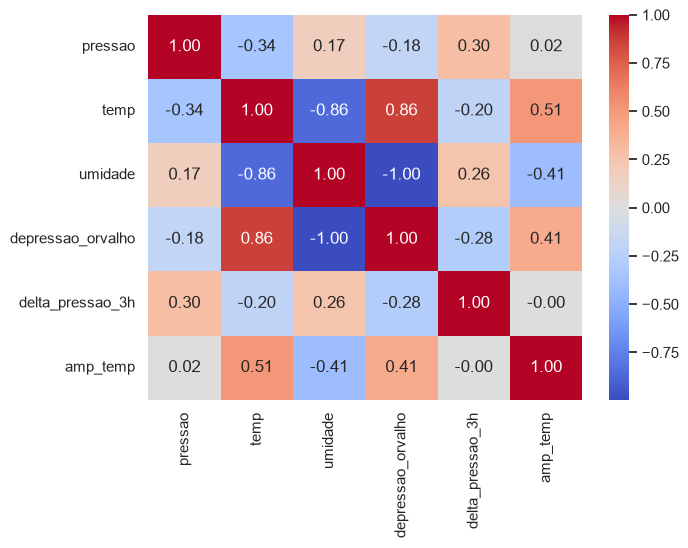

In [21]:
df_recife["depressao_orvalho"] = df_recife["temp"] - df_recife["orvalho"]
df_recife["delta_pressao_3h"] = df_recife["pressao"] - df_recife["pressao"].shift(3)
df_recife["amp_temp"] = df_recife["temp_max"] - df_recife["temp_min"]

variaveis = ["pressao", "temp", "umidade", "depressao_orvalho", "delta_pressao_3h", "amp_temp"]

plt.figure(figsize=(7, 5))
sns.heatmap(df_recife[variaveis].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

In [22]:
dados = df_recife.dropna(subset=variaveis).copy()
X = StandardScaler().fit_transform(dados[variaveis])
X.shape

(17513, 6)

## Escolhendo o número de clusters
Usamos o **Gaussian Mixture (GMM)**, que agrupa as horas em regimes elípticos que podem se sobrepor. Comparamos de 2 a 8 clusters.

In [23]:
resultados = []
amostra = np.random.RandomState(42).choice(len(X), 5000, replace=False)

for k in range(2, 9):
    gmm = GaussianMixture(n_components=k, n_init=3, random_state=42).fit(X)
    labels = gmm.predict(X)
    resultados.append({
        "k": k,
        "bic": gmm.bic(X),
        "silhouette": silhouette_score(X[amostra], labels[amostra]),
        "davies_bouldin": davies_bouldin_score(X, labels),
    })

resultados = pd.DataFrame(resultados)
resultados.round(3)

,k,bic,silhouette,davies_bouldin
0,2,140772.729,0.348,1.141
1,3,122879.189,0.230,1.520
2,4,116215.948,0.226,1.596
3,5,114608.286,0.188,1.441
4,6,109801.530,0.164,1.583
5,7,107838.584,0.152,1.624
6,8,107082.611,0.139,1.775


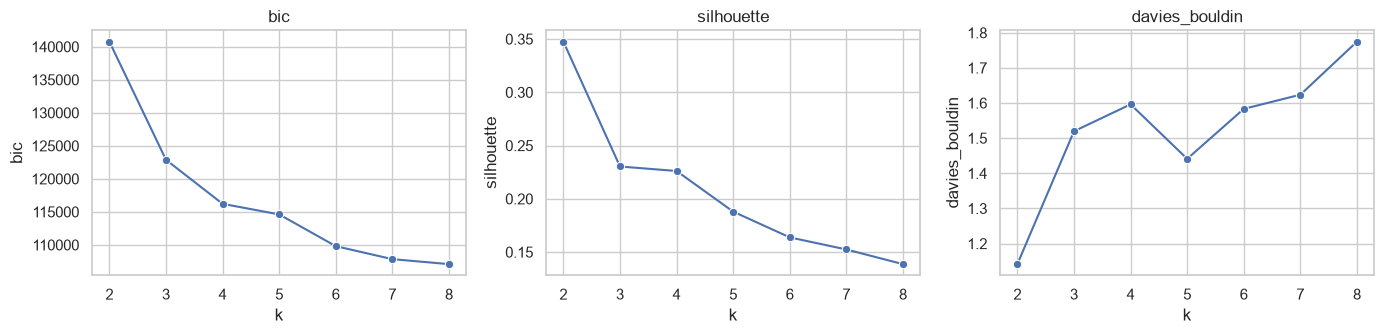

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, metrica in zip(ax, ["bic", "silhouette", "davies_bouldin"]):
    sns.lineplot(data=resultados, x="k", y=metrica, marker="o", ax=a)
    a.set_title(metrica)
plt.tight_layout()
plt.show()

O BIC cai pouco depois de 4 clusters e o silhouette se mantém até 4, então usamos **k = 4**.

## Modelo final

In [25]:
gmm = GaussianMixture(n_components=4, n_init=10, random_state=42).fit(X)
dados["cluster"] = gmm.predict(X)

# numera os clusters do mais seco para o mais úmido
ordem = dados.groupby("cluster")["umidade"].mean().sort_values().index
dados["cluster"] = dados["cluster"].map({antigo: novo for novo, antigo in enumerate(ordem)})

dados["cluster"].value_counts().sort_index()

cluster
0    5338
1    4060
2    3506
3    4609
Name: count, dtype: int64

## Visualizando os clusters

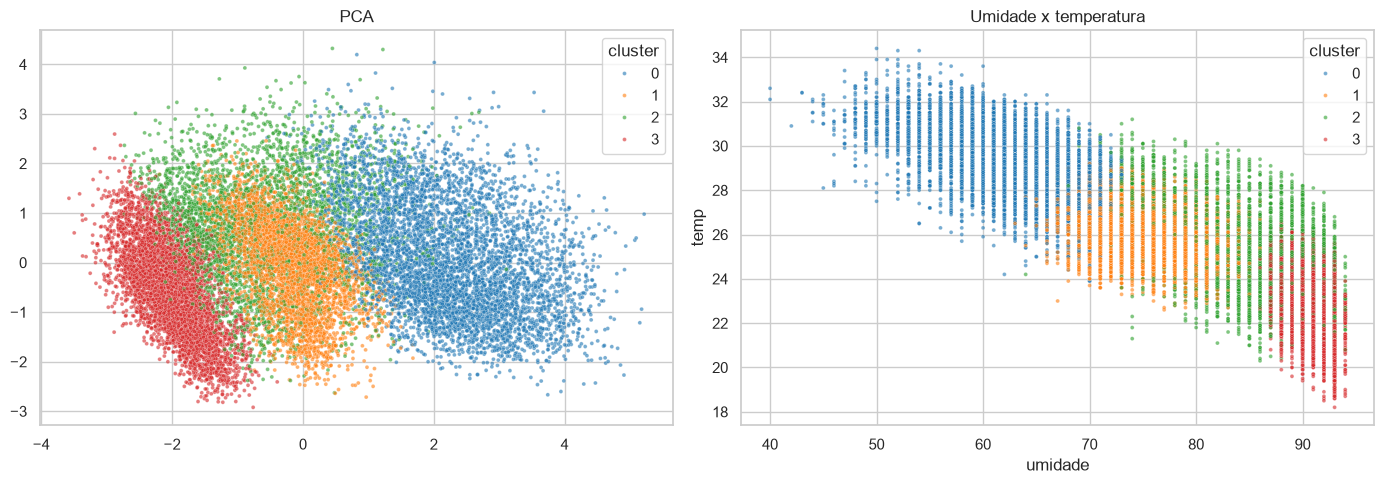

In [26]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=dados["cluster"], palette="tab10", s=8, alpha=0.6, ax=ax[0])
ax[0].set_title("PCA")
sns.scatterplot(data=dados, x="umidade", y="temp", hue="cluster", palette="tab10", s=8, alpha=0.6, ax=ax[1])
ax[1].set_title("Umidade x temperatura")
plt.tight_layout()
plt.show()

## Perfil de cada cluster

In [27]:
perfil = dados.groupby("cluster")[variaveis].mean().round(2)
perfil["horas"] = dados["cluster"].value_counts().sort_index()
perfil

,pressao,temp,umidade,depressao_orvalho,delta_pressao_3h,amp_temp,horas
cluster,,,,,,,
0,1012.35,29.33,61.59,8.22,-0.67,1.63,5338
1,1012.54,26.05,75.09,4.78,0.50,0.58,4060
2,1013.43,25.40,83.77,2.99,0.53,1.78,3506
3,1012.93,23.11,91.12,1.53,-0.07,0.39,4609


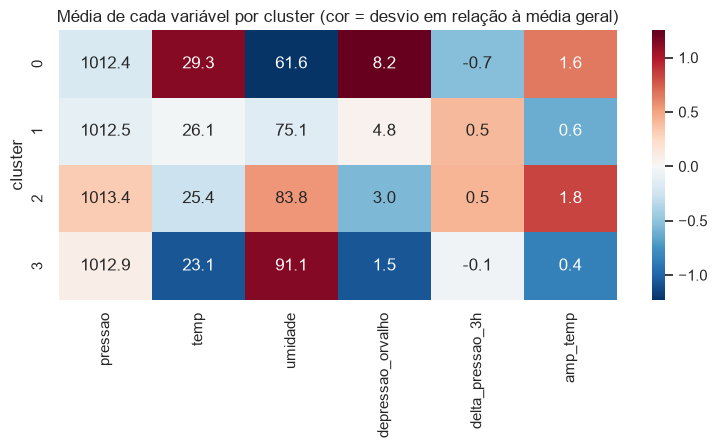

In [28]:
z = (perfil[variaveis] - dados[variaveis].mean()) / dados[variaveis].std()

plt.figure(figsize=(9, 3.5))
sns.heatmap(z, annot=perfil[variaveis], fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Média de cada variável por cluster (cor = desvio em relação à média geral)")
plt.show()

## Quando cada cluster acontece
O horário do dataset está em UTC, então subtraímos 3 horas para ter a hora de Recife.

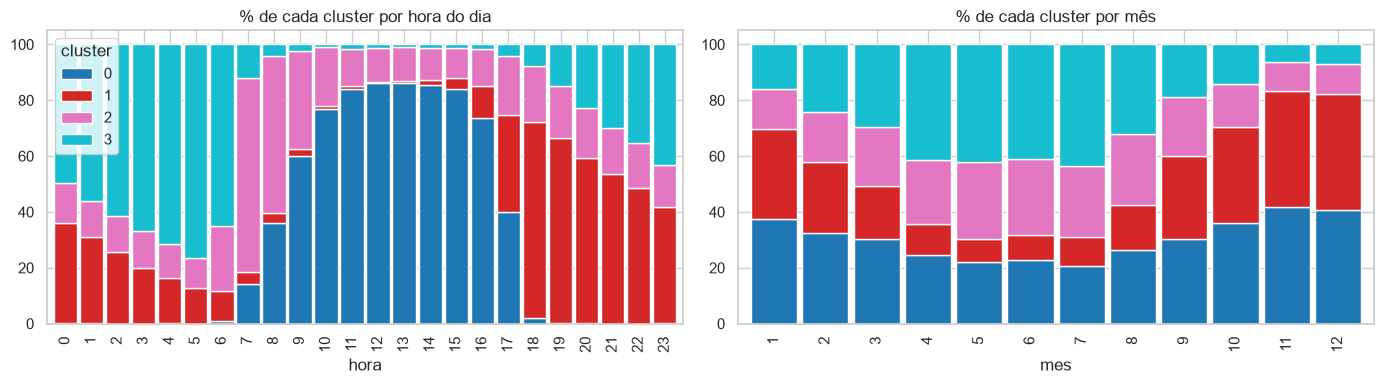

In [29]:
dados["hora"] = (dados["datetime"].dt.hour - 3) % 24
dados["mes"] = dados["datetime"].dt.month

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
pd.crosstab(dados["hora"], dados["cluster"], normalize="index").mul(100).plot(kind="bar", stacked=True, colormap="tab10", ax=ax[0], width=0.9)
ax[0].set_title("% de cada cluster por hora do dia")
pd.crosstab(dados["mes"], dados["cluster"], normalize="index").mul(100).plot(kind="bar", stacked=True, colormap="tab10", ax=ax[1], width=0.9, legend=False)
ax[1].set_title("% de cada cluster por mês")
plt.tight_layout()
plt.show()

## Relação com a chuva
Agora usamos a chuva só para conferir se os clusters separam bem as horas chuvosas das secas.

In [30]:
chuva = dados.dropna(subset=["chuva"])

tabela = chuva.groupby("cluster")["chuva"].agg(
    horas="size",
    pct_com_chuva=lambda s: round((s > 0).mean() * 100, 1),
    chuva_media_mm=lambda s: round(s.mean(), 3),
)
tabela

,horas,pct_com_chuva,chuva_media_mm
cluster,,,
0,5338,1.2,0.007
1,4060,1.4,0.005
2,3506,22.5,0.409
3,4609,28.9,0.488


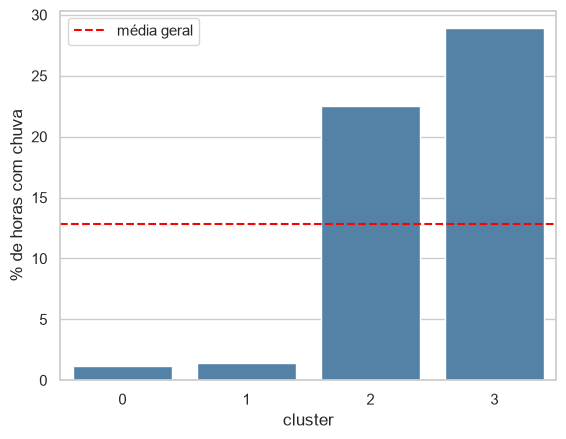

In [31]:
sns.barplot(data=tabela.reset_index(), x="cluster", y="pct_com_chuva", color="steelblue")
plt.axhline((chuva["chuva"] > 0).mean() * 100, color="red", linestyle="--", label="média geral")
plt.ylabel("% de horas com chuva")
plt.legend()
plt.show()

## Conclusão
- Cluster 0: tarde quente e seca. Quase não chove.
- Cluster 1: noite estável. Quase não chove.
- Cluster 2: manhã úmida, com grande amplitude de temperatura. Chove em cerca de 22% das horas.
- Cluster 3: madrugada úmida e fria. É o mais chuvoso, com cerca de 29% das horas com chuva.

Os clusters 2 e 3 concentram a maior parte das chuvas e podem ser usados como variável no modelo de previsão. Parte dessa separação vem da estação chuvosa (abril a agosto) e do horário do dia, então vale comparar com o mês e a hora no modelo.